# The confidence check (slice M3): calibration, from the run log

For a patient who is not starting to deteriorate, at most 1 in 100 of their 15-minute checks (alpha = 0.01) should show a
supported alert, on average over patients. The check calibrates one score quantile *q* on one randomly drawn negative bin
per stay, then calls a student alert supported only when p is above both the student's threshold *t* and *q*. This
notebook only reads the run log (`training/runs/confidence_check/`) and, when it exists, the held-out JSON file that is
written once. It computes no new number. **Synthetic, not validated.**

In [1]:
# Finds the repository root (the folder that holds models/ and training/). This notebook only reads and draws.
import json
import logging
import re
from pathlib import Path

logging.getLogger("matplotlib").setLevel(logging.ERROR)
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from matplotlib.ticker import MaxNLocator

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "models").is_dir() and (p / "training").is_dir())
COLORS = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]  # Okabe-Ito
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 9})


def ints(*axes):
    """Whole numbers on the x axis (generations and epochs)."""
    for ax in axes:
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))


def newest_log(model):
    """The run log with the newest file name under training/runs/<model>/ (the names carry the date)."""
    logs = sorted((ROOT / "training" / "runs" / model).glob("*.json"))
    return json.loads(logs[-1].read_text()), logs[-1].name


In [2]:
log, log_name = newest_log("confidence_check")
CC = ROOT / "models" / "tier_c" / "confidence_check"
LABEL = {"all": "with temperature", "no_temp": "without temperature"}
print(f"run log {log_name}: run id {log['run_id']}, commit {log['commit']}")
print(f"alpha {log['alpha']}, draw seed {log['draw_seed']}, calibration seeds {log['calibration_seeds'][0]}-{log['calibration_seeds'][-1]} ({len(log['calibration_seeds'])} trials)")
for tag, why in log["not_applicable"].items():
    print(f"{LABEL.get(tag, tag)}: not applicable ({why}); no calibration")

run log m3-20261113-fbd39f2.json: run id m3-20261113-fbd39f2, commit fbd39f2
alpha 0.01, draw seed 20261113, calibration seeds 301-340 (40 trials)


## The calibration scores

The student's score for one drawn negative bin per stay, sorted (the run log keeps at most 200 evenly spaced order statistics). *q* is the k-th smallest of the n drawn scores, k = n + 1 - j with j = floor(alpha (n + 1)). *t* is the student's alert threshold. If q is below t the check is not binding and removes no alert.

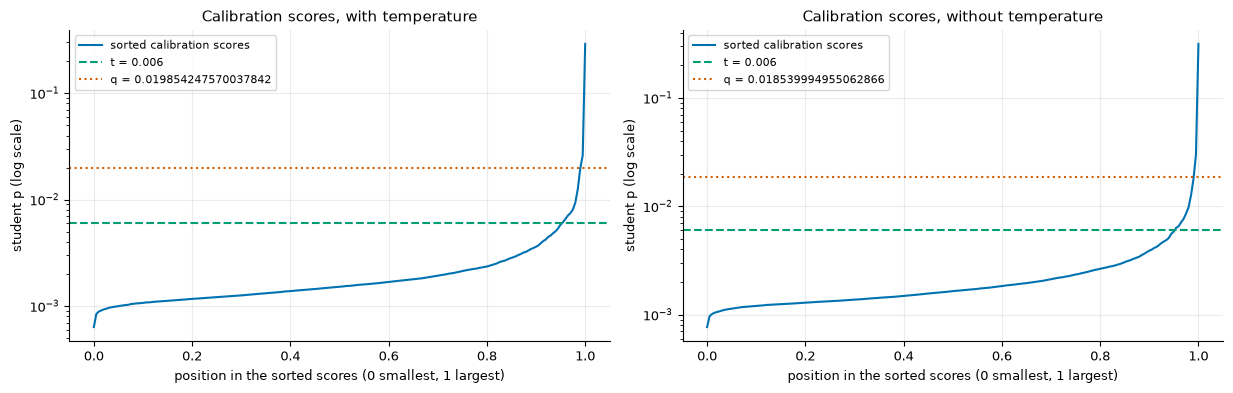

Reading (with temperature): n = 3238 stays drawn from 1257362 negative bins, j = 32, k = 3207, q = 0.019854247570037842, t = 0.006; binding: the check can remove alerts.
Reading (without temperature): n = 3238 stays drawn from 1257362 negative bins, j = 32, k = 3207, q = 0.018539994955062866, t = 0.006; binding: the check can remove alerts.


In [3]:
tags = list(log["variants"])
fig, axes = plt.subplots(1, max(len(tags), 1), figsize=(6.2 * max(len(tags), 1), 4), squeeze=False)
for ax, tag in zip(axes[0], tags):
    v = log["variants"][tag]
    s = v["score_quantiles"]
    ax.plot([i / (len(s) - 1) if len(s) > 1 else 0 for i in range(len(s))], [max(x, 1e-12) for x in s], "-", color="#0072B2", label="sorted calibration scores")
    ax.axhline(v["t"], color="#009E73", ls="--", label=f"t = {v['t']}")
    if v["q"] is not None:
        ax.axhline(v["q"], color="#D55E00", ls=":", label=f"q = {v['q']}")
    ax.set_yscale("log")
    ax.set_title(f"Calibration scores, {LABEL.get(tag, tag)}")
    ax.set_xlabel("position in the sorted scores (0 smallest, 1 largest)")
    ax.set_ylabel("student p (log scale)")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
for tag in tags:
    v = log["variants"][tag]
    q = "infinity (j = 0: nothing is supported)" if v["q"] is None else v["q"]
    print(f"Reading ({LABEL.get(tag, tag)}): n = {v['n']} stays drawn from {v['negative_bins']} negative bins, j = {v['j']}, k = {v['k']}, q = {q}, t = {v['t']}; "
          + ("binding: the check can remove alerts." if v["binding"] else "not binding (q is below t): the check removes no alert."))

## The held-out result

When `heldout.json` exists (written once by `research.confidence evaluate --json` on ward-v2 seeds 11-30), the tables below are read from it: the achieved error against alpha and the verdict as written, the share of bins that are "not sure", the alerting bins, the new alerts and the episodes the check loses, and then the checked rows next to the unchecked ones. Nothing here is computed from trials. Until the file exists this section says so and shows no number.

In [4]:
def f3(x):
    return "none" if x is None else f"{x:.3f}"


def rule_row(label, r):
    """One row of a held-out table, copied from the JSON as written (rounded to 3 places)."""
    a, p = r["per_shift"], r["any_bin"]
    lead = r["lead"]["median"]
    return (f"| {label} | {f3(a['value'])} ({f3(a['lo'])} to {f3(a['hi'])}) | {f3(r['time_in_alert']['rate'])} "
            f"| {f3(p['rate'])} ({f3(p['lo'])} to {f3(p['hi'])}) | {f3(r['chance_any']['rate'])} "
            f"| {f3(r['excess_any_not_cut_short'])} | {'none' if lead is None else f'{lead:.1f}'} |")


def rule_table(rules, rows):
    head = ["| rule | alerts per patient per 12 h (95% interval) | time in alert | alerting in any bin, all evaluated episodes (95% interval) "
            "| chance rate | excess over chance, episodes not cut short | median lead, minutes |", "|---|---|---|---|---|---|---|"]
    return "\n".join(head + [rule_row(label, rules[i]) for label, i in rows if i in rules])


held = CC / "heldout.json"
if not held.exists():
    display(Markdown("**No held-out file is in this repository.** The check is calibrated and not evaluated here, so there is no held-out number."))
else:
    H = json.loads(held.read_text())
    R = {r["id"]: r for r in H["rules"]}
    c = H["context"]
    print(f"held-out seeds {c['held_out_seeds'][0]}-{c['held_out_seeds'][-1]} , {c['episodes_evaluated']} episodes evaluated")
    f4 = lambda x: f"{x:.4f}"
    for tag, v in H["confidence"].items():
        e, ns, ab, na, lo = v["achieved_error"], v["not_sure"], v["alerting_bins"], v["new_alerts"], v["lost"]["all"]
        rows = ["| quantity | value |", "|---|---|",
                f"| achieved error (95% stay-bootstrap interval) | {f4(e['mean'])} ({f4(e['lo'])} to {f4(e['hi'])}) |",
                f"| alpha | {v['alpha']} |", f"| bound for the verdict | {f4(v['bound'])} |", f"| verdict, as written | {v['verdict']} |",
                f"| not sure, of scored bins | {ns['bins']} of {ns['of_scored_bins']} ({f4(ns['bins'] / ns['of_scored_bins'])}) |",
                f"| not sure, of the student's alerting bins | {ns['bins']} of {ns['of_student_alerting_bins']} ({f4(ns['bins'] / ns['of_student_alerting_bins'])}) |",
                f"| alerting bins, student / checked | {ab['student']} / {ab['checked']} |", f"| new alerts, student / checked | {na['student']} / {na['checked']} |",
                f"| episodes lost: alerting in any bin / caught early | {lo['any']} / {lo['early']} |"]
        display(Markdown(f"**{LABEL[tag]}**\n\n" + "\n".join(rows)))
    pairs = [("student", "student"), ("student, checked", "student_checked"), ("NEWS2 or student", "news2_or_student"), ("NEWS2 or student, checked", "news2_or_student_checked")]
    display(Markdown("**Checked and unchecked rows, with temperature**\n\n" + rule_table(R, pairs)))
    display(Markdown("**Checked and unchecked rows, without temperature**\n\n" + rule_table(R, [(a, b + "_no_temp") for a, b in pairs])))


held-out seeds 11-30 , 91 episodes evaluated


**with temperature**

| quantity | value |
|---|---|
| achieved error (95% stay-bootstrap interval) | 0.0065 (0.0057 to 0.0074) |
| alpha | 0.01 |
| bound for the verdict | 0.0135 |
| verdict, as written | MET |
| not sure, of scored bins | 27523 of 663089 (0.0415) |
| not sure, of the student's alerting bins | 27523 of 46103 (0.5970) |
| alerting bins, student / checked | 46103 / 18580 |
| new alerts, student / checked | 6247 / 1930 |
| episodes lost: alerting in any bin / caught early | 8 / 13 |

**without temperature**

| quantity | value |
|---|---|
| achieved error (95% stay-bootstrap interval) | 0.0067 (0.0058 to 0.0076) |
| alpha | 0.01 |
| bound for the verdict | 0.0135 |
| verdict, as written | MET |
| not sure, of scored bins | 28792 of 663089 (0.0434) |
| not sure, of the student's alerting bins | 28792 of 46875 (0.6142) |
| alerting bins, student / checked | 46875 / 18083 |
| new alerts, student / checked | 6188 / 1926 |
| episodes lost: alerting in any bin / caught early | 9 / 13 |

**Checked and unchecked rows, with temperature**

| rule | alerts per patient per 12 h (95% interval) | time in alert | alerting in any bin, all evaluated episodes (95% interval) | chance rate | excess over chance, episodes not cut short | median lead, minutes |
|---|---|---|---|---|---|---|
| student | 0.413 (0.394 to 0.430) | 0.064 | 0.670 (0.570 to 0.762) | 0.319 | 0.415 | 59.5 |
| student, checked | 0.128 (0.116 to 0.140) | 0.026 | 0.582 (0.473 to 0.681) | 0.089 | 0.544 | 20.5 |
| NEWS2 or student | 0.525 (0.507 to 0.543) | 0.185 | 0.747 (0.655 to 0.831) | 0.580 | 0.243 | 66.0 |
| NEWS2 or student, checked | 0.438 (0.418 to 0.457) | 0.165 | 0.692 (0.593 to 0.782) | 0.491 | 0.268 | 44.6 |

**Checked and unchecked rows, without temperature**

| rule | alerts per patient per 12 h (95% interval) | time in alert | alerting in any bin, all evaluated episodes (95% interval) | chance rate | excess over chance, episodes not cut short | median lead, minutes |
|---|---|---|---|---|---|---|
| student | 0.409 (0.391 to 0.427) | 0.065 | 0.681 (0.576 to 0.773) | 0.329 | 0.418 | 48.8 |
| student, checked | 0.127 (0.115 to 0.139) | 0.025 | 0.582 (0.473 to 0.681) | 0.091 | 0.542 | 16.1 |
| NEWS2 or student | 0.512 (0.494 to 0.530) | 0.183 | 0.747 (0.651 to 0.835) | 0.577 | 0.246 | 66.0 |
| NEWS2 or student, checked | 0.433 (0.413 to 0.452) | 0.165 | 0.692 (0.593 to 0.782) | 0.491 | 0.268 | 44.6 |

### Reading

The held-out seeds were **scored once**. The achieved error is a mean over stays of the share of negative bins with a supported alert. With temperature it is 0.0065, below alpha, 0.01, and the verdict is written as MET. MET is the word of the pre-registered rule (the lower end of the interval is at most the bound), not a guarantee. The check removes 0.597 of the student's alerting bins and loses a few episodes. Read the checked rows against the unchecked ones: they alert less, spend less time in alert, and find fewer episodes. The data are simulated. **Synthetic, not validated.**